# DAY3 실습 02 — 가설검정과 일표본 t검정

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Mounted at /content/drive


## 데이터와 질문

데이터 파일 : `ai4i2020.csv`
출처 : UCI Machine Learning Repository - [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)



| 열 | 뜻 |
|---|---|
| `Torque [Nm]` | 토크 (N·m) |
| `Rotational speed [rpm]` | 회전속도 (rpm, 분당 회전수) |
| `Tool wear [min]` | 공구 사용시간 (분). 공구를 교체하면 0부터 다시 쌓인다 |

**질문** : 운전 기록에서 뽑은 표본으로 볼 때, 모집단의 평균 토크가 기준값 40 N·m와 다르다고 할 수 있는가?

**실습 전제** : 기준값 40 N·m와 공구 사용시간 · 회전속도의 기준값은 학습을 위한 가상 기준이며 실제 설비 규격이 아니다. 실제 분석처럼 모평균을 모른다고 보고, 표본만으로 판단한다.

In [ ]:
# 데이터 확인 : 행·열 수와 분석할 두 열의 결측
print("행·열:", data.shape)                                         # shape : (행 수, 열 수)
print("토크 결측:", data["Torque [Nm]"].isna().sum())                # 결측이 있으면 검정 결과가 NaN 으로 나오므로 먼저 확인한다
print("회전속도 결측:", data["Rotational speed [rpm]"].isna().sum())
print("공구 사용시간 결측:", data["Tool wear [min]"].isna().sum())

행·열: (10000, 14)
토크 결측: 0
회전속도 결측: 0
공구 사용시간 결측: 0


## 1. 가설검정의 흐름

**가설검정**은 모집단에 대한 주장(가설)을 세운 뒤, 표본 데이터로 그 주장을 기각할 근거가 있는지 통계적으로 판단하는 과정이다.

| 용어 | 뜻 | 공정시간 예 (30건) |
|---|---|---|
| 귀무가설 H₀ | "차이가 없다", "효과가 없다"처럼 검정의 기준이 되는 가설 | 평균 공정시간은 50분이다. (μ = 50) |
| 대립가설 H₁ | 입증하려는 주장. "차이가 있다", "효과가 있다" | 평균 공정시간은 50분과 다르다. (μ ≠ 50) |
| 검정통계량 | 표본 데이터로 계산하여 관측 결과가 귀무가설에서 얼마나 벗어났는지를 하나의 숫자로 나타낸 값 | t = 2.22 |
| 유의수준 α | 귀무가설이 맞는데도 기각하는 잘못을 어디까지 허용할지 정한 기준. 보통 0.05 | α = 0.05 |
| p값 | 귀무가설이 맞다고 할 때, 이번 결과 또는 더 극단적인 결과가 나올 확률 | p = 0.0346 |

**가설검정 4단계**

1) 가설 설정 : 귀무가설(H₀)과 대립가설(H₁)을 문장과 기호로 쓴다. 예) 귀무가설(H₀): 평균 공정시간은 50분이다. (μ = 50)
2) 유의수준 결정 : 데이터를 보기 전에 α와 검정 방향(양측·단측)을 정한다
3) 검정통계량과 p값 계산
4) 결과 도출 : p값 < α 이면 H₀를 기각하고, p값 ≥ α 이면 H₀를 기각하지 못한다

**검정통계량 t** : 표본평균이 기준값에서 표준오차 몇 개만큼 떨어져 있는지 나타낸다.

t = (표본평균 − 기준값) ÷ 표준오차, 자유도 = n − 1

**주요 함수와 인자**

| 함수 | 기능 |
|---|---|
| `stats.ttest_1samp(x, popmean=기준값)` | 일표본 t검정. t값, p값, 자유도를 한 번에 계산한다 |
| `결과.statistic` · `결과.pvalue` · `결과.df` | 검정통계량 t, p값, 자유도 |
| `stats.t.sf(t값, df=자유도)` | t분포에서 t값보다 큰 값이 나올 확률(오른쪽 꼬리 넓이). 양측검정은 양쪽 꼬리를 보므로 2배 해서 p값을 구한다 |

공식 문서 : [scipy.stats.ttest_1samp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html) · [scipy.stats.t](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html) · [NIST : Hypothesis tests](https://www.itl.nist.gov/div898/handbook/prc/section1/prc13.htm)

In [ ]:
# [예제] 공정시간 30건으로 평균이 기준값 50분과 다른지 검정한다
# 귀무가설(H₀): 평균 공정시간은 50분이다. (μ = 50)
# 대립가설(H₁): 평균 공정시간은 50분과 다르다. (μ ≠ 50)
# 유의수준 α = 0.05, 양측
x = np.array([53, 43, 60, 61, 44, 52, 52, 62, 54, 46, 52, 53, 52, 45, 50,
              59, 60, 43, 50, 51, 55, 52, 52, 54, 52, 48, 54, 50, 59, 46])   # 공정시간 30건 (분)
mu0 = 50                                                     # 귀무가설의 기준값 μ₀
n_x = len(x)                                                 # 표본 크기 30
se_x = stats.sem(x)                                          # 표준오차 = s ÷ √n
t_value = (x.mean() - mu0) / se_x                            # 검정통계량 t = (표본평균 − 기준값) ÷ 표준오차
p_value = 2 * stats.t.sf(abs(t_value), df=n_x - 1)           # sf : t값 바깥(오른쪽) 꼬리 넓이. 양측이므로 2배 / abs : 절댓값
print("표본평균:", round(x.mean(), 2), "/ 표준오차:", round(se_x, 3))
print("직접 계산 → t:", round(t_value, 3), "/ p값:", round(p_value, 4))

result = stats.ttest_1samp(x, popmean=mu0)                   # 같은 계산을 함수 한 줄로
print("ttest_1samp → t:", round(result.statistic, 3), "/ p값:", round(result.pvalue, 4), "/ 자유도:", result.df)

# [결과]
# - t = 2.217, p = 0.0346
# - 통계적 결론 : p = 0.0346 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 평균 공정시간은 50분과 다르다고 볼 통계적 근거가 있다 (표본평균 52.13분, n = 30)

표본평균: 52.13 / 표준오차: 0.962
직접 계산 → t: 2.217 / p값: 0.0346
ttest_1samp → t: 2.217 / p값: 0.0346 / 자유도: 29


### 결론

| 구분 | 쓰는 내용 | 공정시간 예 |
|---|---|---|
| 통계적 결론 | p값과 유의수준을 비교한 판단 | p = 0.0346 < 0.05 이므로 귀무가설을 기각한다 |
| 사실적 결론 | 가설 문장으로 바꾼 결론 + 관측값 | 평균 공정시간은 50분과 다르다고 볼 통계적 근거가 있다 (표본평균 52.13분, n = 30) |

p값 ≥ α 이면 통계적 결론은 "귀무가설을 기각하지 못한다", 사실적 결론은 "~와 다르다고 볼 통계적 근거가 부족하다"로 쓴다.

## 2. 유의수준, 오류, 검정 방향
**기각역**은 H₀가 맞다면 우연히 나올 가능성이 매우 낮은 검정통계량의 영역이고, **임계값**은 기각역이 시작되는 경계값이다. 공정시간 예(자유도 29, α = 0.05 양측)의 임계값은 ±2.045이고, 기각역은 t ≤ −2.045 또는 t ≥ 2.045다. t = 2.22는 2.045보다 커서 기각역 안에 들어가므로 귀무가설을 기각한다. α(유의수준)는 데이터를 보기 전에 정하고, 결과를 본 뒤 바꾸지 않는다.

**제1종 오류와 제2종 오류** : 표본으로 판단하므로 결론은 틀릴 수 있다.

| 검정 결과 \ 실제 | H₀ 가 참 | H₀ 가 거짓 |
|---|---|---|
| H₀ 를 기각하지 못함 | 옳은 결정 | **제2종 오류** (확률 β) : 실제 차이를 놓친다 |
| H₀ 를 기각 | **제1종 오류** (확률 α) : 차이가 없는데 있다고 판단한다 | 옳은 결정 (확률 1 − β = **검정력**) |

**로트 검사로 보는 두 오류**

**로트(lot)** : 같은 조건(같은 원자재 · 설비 · 작업 시간대)에서 만들어져 하나의 묶음으로 관리 · 검사 · 출하되는 제품 단위다. 예를 들어 "3월 5일 주간조 1번 라인 생산품 2,000개"가 한 로트다. 로트의 제품을 모두 검사하기 어려우므로 일부를 표본으로 뽑아 검사하고, 그 결과로 로트 전체의 합격 · 불합격을 판정한다.

| 검정 용어 | 로트 검사에서의 뜻 | 결과 |
|---|---|---|
| 귀무가설(H₀) | 이 로트는 정상이다 (불량률이 기준 이하) | |
| 대립가설(H₁) | 이 로트는 비정상이다 (불량률이 기준 초과) | |
| 제1종 오류 (α) | 정상 로트를 불합격 처리한다 · **생산자 위험** (생산자가 손해를 본다) | 멀쩡한 제품을 재검사 · 폐기한다 |
| 제2종 오류 (β) | 불량 로트를 합격 처리한다 · **소비자 위험** (소비자가 손해를 본다) | 불량품이 고객에게 출하되어 클레임이 생긴다 |
| 검정력 (1 − β) | 불량 로트를 불합격으로 걸러낼 확률 | |


- 표본 크기가 같으면 α를 낮출수록 제1종 오류는 줄지만 제2종 오류는 늘어난다. 두 오류를 함께 줄이려면 표본을 늘린다.
- 검정력은 표본이 많을수록, 실제 차이가 클수록, 산포가 작을수록, α가 클수록 커진다.
- 검정력이 높아도 오류가 전혀 없는 것은 아니다.

**검정 방향** : 데이터를 보기 전에 정한다.
alternative는 대립가설(H₁)의 방향을 지정한다.

| 질문 | 가설 | `alternative` | 임계값 (자유도 29) |
|---|---|---|---|
| 기준값과 다른가? (양측) | 귀무가설(H₀): 평균은 50분이다. (μ = 50)<br>대립가설(H₁): 평균은 50분과 다르다. (μ ≠ 50) | `"two-sided"` (기본값) | ±2.045 (양쪽에 2.5%씩) |
| 기준값보다 큰가? (오른쪽 단측) | 귀무가설(H₀): 평균은 50분 이하다. (μ ≤ 50)<br>대립가설(H₁): 평균은 50분보다 길다. (μ > 50) | `"greater"` | +1.699 (한쪽에 5%) |
| 기준값보다 작은가? (왼쪽 단측) | 귀무가설(H₀): 평균은 50분 이상이다. (μ ≥ 50)<br>대립가설(H₁): 평균은 50분보다 짧다. (μ < 50) | `"less"` | −1.699 (한쪽에 5%) |

공식 문서 : [scipy.stats.ttest_1samp (alternative)](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html) · [NIST : Critical values of the t distribution](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3672.htm) · [NIST : Type I and Type II errors](https://www.itl.nist.gov/div898/handbook/prc/section1/prc131.htm) · [NIST : Acceptance sampling](https://www.itl.nist.gov/div898/handbook/pmc/section2/pmc21.htm)

In [ ]:
# [예제] 같은 공정시간 30건에서 검정 방향만 바꿔 p값을 비교한다 (유의수준 α = 0.05)

# 양측
# 귀무가설(H₀): 평균 공정시간은 50분이다. (μ = 50)
# 대립가설(H₁): 평균 공정시간은 50분과 다르다. (μ ≠ 50)
print("양측 (μ ≠ 50):", round(stats.ttest_1samp(x, 50, alternative="two-sided").pvalue, 4))   # 50과 다른가

# 오른쪽 단측
# 귀무가설(H₀): 평균 공정시간은 50분 이하다. (μ ≤ 50)
# 대립가설(H₁): 평균 공정시간은 50분보다 길다. (μ > 50)
print("오른쪽 (μ > 50):", round(stats.ttest_1samp(x, 50, alternative="greater").pvalue, 4))   # 50보다 큰가

# 왼쪽 단측
# 귀무가설(H₀): 평균 공정시간은 50분 이상이다. (μ ≥ 50)
# 대립가설(H₁): 평균 공정시간은 50분보다 짧다. (μ < 50)
print("왼쪽 (μ < 50):", round(stats.ttest_1samp(x, 50, alternative="less").pvalue, 4))       # 50보다 작은가

print("양측 임계값:", round(stats.t.ppf(0.975, df=29), 3))    # 양쪽 꼬리 2.5% 씩 → 왼쪽부터 97.5% 지점
print("단측 임계값:", round(stats.t.ppf(0.95, df=29), 3))     # 한쪽 꼬리 5% → 왼쪽부터 95% 지점


# [결과]
# - 양측 : p = 0.0346 < 0.05
#   통계적 결론 : 귀무가설을 기각한다
#   사실적 결론 : 평균 공정시간은 50분과 다르다고 볼 통계적 근거가 있다
# - 오른쪽 단측 : p = 0.0173 < 0.05
#   통계적 결론 : 귀무가설을 기각한다
#   사실적 결론 : 평균 공정시간은 50분보다 길다고 볼 통계적 근거가 있다
# - 왼쪽 단측 : p = 0.9827 ≥ 0.05
#   통계적 결론 : 귀무가설을 기각하지 못한다
#   사실적 결론 : 평균 공정시간은 50분보다 짧다고 볼 통계적 근거가 부족하다

양측 (μ ≠ 50): 0.0346
오른쪽 (μ > 50): 0.0173
왼쪽 (μ < 50): 0.9827
양측 임계값: 2.045
단측 임계값: 1.699


## 3. p값과 신뢰구간으로 판단하기

**p값의 뜻** : H₀가 참이라고 가정했을 때 지금 결과만큼 또는 더 극단적인 결과가 나올 확률이다. H₀가 참일 확률을 나타내지 않는다.

| 결과 | 판단 | 말할 수 있는 것 |
|---|---|---|
| p < α | H₀를 기각한다 | 기준값과 다르다고 볼 근거가 있다 |
| p ≥ α | H₀를 기각하지 못한다 | 기각할 근거가 충분하지 않다. "차이가 없다"를 증명한 것은 아니다 |

**두 가지 확인 방법** : 같은 양측검정, 같은 α에서는 결론이 같다.

| 방법 | 기각 조건 | 보여 주는 것 |
|---|---|---|
| p값 | p < α | 차이가 있는가 |
| 95% 신뢰구간 | 기준값이 구간 밖에 있다 | 차이가 얼마나 되는가 |

| 함수 | 기능 |
|---|---|
| `결과.confidence_interval(confidence_level=0.95)` | 검정 결과에서 모평균의 신뢰구간을 꺼낸다. `.low` · `.high`가 하한과 상한 |

공식 문서 : [scipy.stats.ttest_1samp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html) · [ASA Statement on p-Values](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf)

In [ ]:
# [예제] 공정시간 30건 : 신뢰구간으로도 같은 결론이 나오는지 확인한다
# 귀무가설(H₀): 평균 공정시간은 50분이다. (μ = 50)
# 대립가설(H₁): 평균 공정시간은 50분과 다르다. (μ ≠ 50)
# 유의수준 α = 0.05 → 95% 신뢰구간
ci = result.confidence_interval(confidence_level=0.95)        # 앞에서 만든 검정 결과(result)에서 95% 신뢰구간을 꺼낸다
print("모평균 95% 신뢰구간:", round(ci.low, 2), "~", round(ci.high, 2), "분")
print("기준값 50 이 구간 안에 있는가:", ci.low <= 50 <= ci.high)                  # 구간 밖이면 False → H₀ 기각과 같은 결론
print("기준값과의 차이 구간:", round(ci.low - 50, 2), "~", round(ci.high - 50, 2), "분")   # 차이의 크기 범위

# [결과]
# - 95% 신뢰구간 50.17 ~ 54.10분, 기준값 50 은 구간 밖에 있다
# - 통계적 결론 : 기준값 50 이 95% 신뢰구간 밖에 있으므로 귀무가설을 기각한다 (p값 0.0346 < 0.05 와 같은 결론)
# - 사실적 결론 : 평균 공정시간은 50분과 다르다고 볼 통계적 근거가 있으며, 기준보다 0.17 ~ 4.10분 길다고 추정된다

모평균 95% 신뢰구간: 50.17 ~ 54.1 분
기준값 50 이 구간 안에 있는가: False
기준값과의 차이 구간: 0.17 ~ 4.1 분


## 4. 질문에 맞는 검정 고르기

**검정 전에 확인하는 순서**

| 순서 | 확인 항목 | 확인 질문 |
|---|---|---|
| 1) | 분석 질문 | 어떤 모집단의 무엇을 비교하려는가 |
| 2) | 분석 단위와 구조 | 독립된 두 집단인가, 같은 대상의 전·후인가 |
| 3) | 수집 과정 | 표본은 현장을 대표하며 관측값은 독립적인가 |
| 4) | 분포와 이상값 | 그래프에서 심한 치우침이나 극단값이 보이는가 |
| 5) | 검정과 보고 | 검정을 선택하고 차이·신뢰구간·p값을 함께 보고한다 |

**평균을 비교하는 세 가지 t검정**

| 검정 | 질문 | 정규성 확인 대상 | 정규성이 크게 어긋나지 않을 때 | 크게 어긋날 때 (비모수) |
|---|---|---|---|---|
| 일표본 t검정 | 한 평균이 기준값과 다른가 | 측정값 그대로 | `stats.ttest_1samp(x, 기준값)` | `stats.wilcoxon(x - 기준값)` |
| 대응표본 t검정 | 같은 대상의 전·후가 다른가 | 전·후 차이 (후 − 전) | `stats.ttest_rel(after, before)` | `stats.wilcoxon(after, before)` |
| Welch t검정 | 독립된 두 집단의 평균이 다른가 | 두 집단 각각 | `stats.ttest_ind(A, B, equal_var=False)` | `stats.mannwhitneyu(A, B)` |


**검정 선택 원칙** : 검정은 정규성 p값 하나로 정하지 않는다. 먼저 비교할 대상(평균인지, 중앙값·분포인지)을 정하고, 표본 크기 · 분포 모양 · 극단값을 함께 본다. Wilcoxon 부호순위검정은 측정값 − 기준값(대응표본은 차이값)의 분포가 대체로 좌우 대칭일 때 쓴다. 한쪽으로 크게 치우치면 부호검정(`stats.binomtest`)으로 중앙값을 검정한다.

**비모수 검정**은 정규분포를 가정하지 않는 검정이다. 극단값이나 한쪽으로 긴 꼬리에 크게 흔들리지 않는다. 평균을 직접 비교하지 않으므로 결과를 "평균이 다르다"로 쓰지 않는다.

공식 문서 : [scipy.stats 검정 함수 목록](https://docs.scipy.org/doc/scipy/reference/stats.html#hypothesis-tests-and-related-functions)

## 5. 정규성 확인

t검정은 표본평균의 분포가 정규분포에 가깝다고 보고 계산한다. 그래서 검정 전에 측정값이 정규분포에서 크게 벗어나지 않는지 확인한다. **그림과 검정을 함께** 본다.

| 확인 방법 | 정규성이 크게 어긋나지 않을 때 | 크게 어긋날 때 |
|---|---|---|
| 히스토그램 | 봉우리가 하나이고 좌우가 대체로 비슷하다 | 한쪽에 몰리고 반대쪽 꼬리가 길다 |
| Q-Q 플롯 | 점이 직선을 따라간다 | 점이 끝에서 직선 밖으로 휘거나 멀리 떨어진 점이 있다 |
| Shapiro-Wilk 검정 | p ≥ 0.05 | p < 0.05 |

**Q-Q 플롯**은 자료의 분위수를 정규분포의 분위수와 짝지어 찍은 그림이다. 점이 직선에 가까울수록 정규분포에 가깝다.

**Shapiro-Wilk 검정**의 가설은 다음과 같다.

- 귀무가설(H₀): 데이터는 정규분포를 따른다.
- 대립가설(H₁): 데이터는 정규분포를 따르지 않는다.

p ≥ 0.05면 이 가설을 기각하지 못하므로 t검정을 쓴다. 정규분포라고 증명된 것은 아니다.

**주의**
- 표본이 작으면 비정규성을 놓칠 수 있고, 표본이 크면 작은 어긋남에도 p < 0.05가 나온다. 정규성 검정의 귀무가설은 "정확히 정규분포다"인데, 실제 데이터는 완전한 정규분포가 아니다. 표본이 클수록 검정이 작은 차이까지 잡아내므로, t검정에 문제가 없을 정도의 어긋남도 기각된다. 그래서 p값과 그림을 함께 해석한다.
- 이 정규성 p값은 검정 방법을 고르기 위한 값이다. 평균을 비교하는 t검정의 p값과 다르다.
- `stats.shapiro`는 보통 데이터 5,000개 이하에 쓴다. 5,000개를 넘으면  `stats.normaltest` 도 대안

| 함수 | 기능 |
|---|---|
| `stats.shapiro(x)` | Shapiro-Wilk 정규성 검정. `.statistic`(W)과 `.pvalue` |
| `stats.probplot(x, dist="norm", plot=축)` | 정규 Q-Q 플롯을 그린다 |

공식 문서 : [scipy.stats.shapiro](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html) · [scipy.stats.probplot](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html) · [NIST : Normal probability plot](https://www.itl.nist.gov/div898/handbook/eda/section3/normprpl.htm)

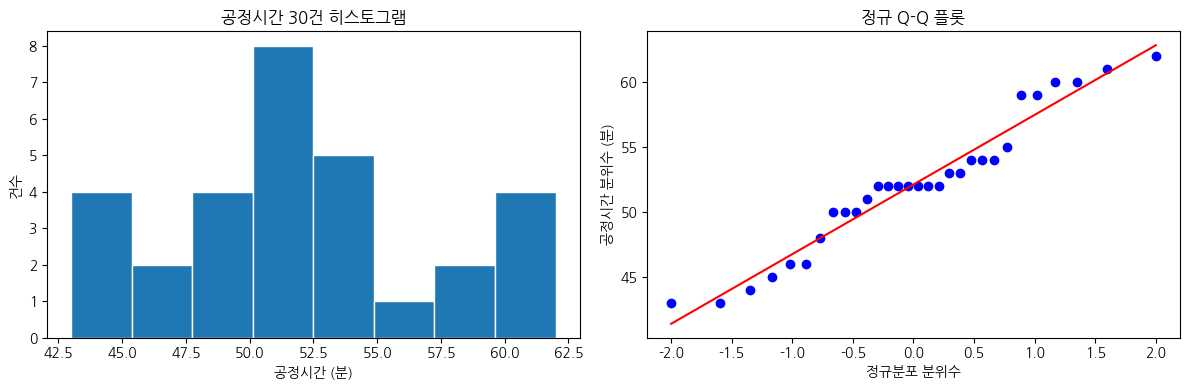

Shapiro-Wilk W: 0.947 / p값: 0.1413


In [ ]:
# [예제] 공정시간 30건의 정규성 : 히스토그램 · Q-Q 플롯 · Shapiro-Wilk 검정
# 귀무가설(H₀): 공정시간은 정규분포를 따른다.
# 대립가설(H₁): 공정시간은 정규분포를 따르지 않는다.
# 유의수준 α = 0.05
fig, axes = plt.subplots(1, 2, figsize=(12, 4))               # 1행 2열 : 왼쪽 히스토그램, 오른쪽 Q-Q 플롯
axes[0].hist(x, bins=8, edgecolor="white")                    # 분포 모양 확인
axes[0].set(title="공정시간 30건 히스토그램", xlabel="공정시간 (분)", ylabel="건수")
stats.probplot(x, dist="norm", plot=axes[1])                  # dist="norm" : 정규분포와 비교 / plot=axes[1] : 오른쪽 칸에 그린다
axes[1].set(title="정규 Q-Q 플롯", xlabel="정규분포 분위수", ylabel="공정시간 분위수 (분)")
plt.tight_layout()
plt.show()

normality = stats.shapiro(x)                                  # Shapiro-Wilk 정규성 검정
print("Shapiro-Wilk W:", round(normality.statistic, 3), "/ p값:", round(normality.pvalue, 4))

# [결과]
# - Shapiro-Wilk p = 0.1413. 히스토그램은 봉우리가 하나이고, Q-Q 점은 대체로 직선을 따라간다
# - 통계적 결론 : p = 0.1413 ≥ 0.05 이므로 귀무가설을 기각하지 못한다
# - 사실적 결론 : 공정시간이 정규분포를 따르지 않는다고 볼 통계적 근거가 부족하다. 그림에서도 크게 어긋나지 않으므로 t검정을 쓴다

In [ ]:
# [실습]
# 상황 : 토크 평균을 기준값과 비교하기 전에, 토크 표본이 t검정을 쓸 수 있는 분포인지 확인한다.
#        귀무가설(H₀): 토크는 정규분포를 따른다.
#        대립가설(H₁): 토크는 정규분포를 따르지 않는다. (α = 0.05)
# 토크 80건(random_state=42)을 뽑아 히스토그램과 Q-Q 플롯을 나란히 그리고, Shapiro-Wilk 검정의 p값을 구하시오.



## 6. 일표본 t검정

**일표본 t검정**은 하나의 표본에서 얻은 평균을 미리 정한 기준값 μ₀와 비교하는 검정이다.

| 기호 | 뜻 |
|---|---|
| x̄ | 표본평균 |
| μ₀ | 기준 평균. 귀무가설에서 비교하는 값 (토크 예 : 40) |
| s | 표본표준편차 |
| n | 표본 크기 (데이터 개수) |
| s ÷ √n | 표준오차 |
| t = (x̄ − μ₀) ÷ (s ÷ √n) | 기준값과의 차이가 표준오차 몇 개만큼인지 나타내는 검정통계량. 자유도 n − 1 |

**토크 80건 검정의 4단계**

1) 가설 설정
   - 귀무가설(H₀): 모집단의 평균 토크는 40 N·m이다. (μ = 40)
   - 대립가설(H₁): 모집단의 평균 토크는 40 N·m와 다르다. (μ ≠ 40)

2) 유의수준 : α = 0.05, 양측
3) 정규성 확인 → 검정 : 앞에서 확인한 대로 크게 어긋나지 않으므로 `stats.ttest_1samp`
4) 결과 도출 : p값과 0.05를 비교하고, 신뢰구간과 함께 결론을 쓴다

공식 문서 : [scipy.stats.ttest_1samp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html)

In [ ]:
# [실습]
# 상황 : 토크 80건으로 모집단의 평균 토크가 기준값 40 N·m와 다른지 검정한다.
#        귀무가설(H₀): 모집단의 평균 토크는 40 N·m이다. (μ = 40)
#        대립가설(H₁): 모집단의 평균 토크는 40 N·m와 다르다. (μ ≠ 40)
#        유의수준 α = 0.05, 양측
# 일표본 t검정으로 표본평균, t, p값, 자유도와 모평균의 95% 신뢰구간을 구하시오.



In [ ]:
# [실습]
# 상황 : 위 검정 결과를 보고서에 두 줄로 정리한다.
# 아래 결론 문장의 빈칸을 채우시오.
#    통계적 결론 : p = ___ ___ 0.05 이므로 귀무가설을 ___________.
#    사실적 결론 : 모집단의 평균 토크가 기준값 40 N·m와 다르다고 볼 통계적 근거가 ______ (표본평균 ___ N·m, 95% 신뢰구간 ___ ~ ___ N·m, n = 80).



## 7. 정규성이 크게 어긋날 때 : 비모수 검정 (Wilcoxon 부호순위검정)

측정값의 정규성이 크게 어긋나면, 일표본 t검정 대신 비모수 검정인 **Wilcoxon 부호순위검정**을 쓴다. 정규분포를 가정하지 않고 순위를 이용한다.

| 항목 | 내용 |
|---|---|
| 계산 방법 | 각 값에서 기준값을 뺀 차이의 **부호**(+, −)와 **크기의 순위**를 이용한다 |
| 사용 조건 | 측정값 − 기준값의 분포가 **대체로 좌우 대칭**이다. 히스토그램(값의 배열)에서 중심 양쪽의 모양이 비슷한지로 확인한다. 평균과 중앙값의 차이는 참고 지표다 |
| 비교 대상 | 중앙값. 대칭인 분포에서는 중앙값이 분포의 중심이다 |
| 가설 형식 | 귀무가설(H₀): 중앙값은 기준값이다. (M = 기준값)<br>대립가설(H₁): 중앙값은 기준값과 다르다. (M ≠ 기준값) |
| 결과 해석 | 결론은 중앙값으로 쓴다. 평균을 비교한 것이 아니므로 "평균이 다르다"로 쓰지 않는다 |

M은 중앙값(median)을 나타내는 기호다. 평균의 기호 μ와 구분한다.

**정규성과 대칭은 다르다** : 정규분포는 좌우 대칭이지만, 좌우 대칭인 분포가 모두 정규분포는 아니다. 값이 고르게 퍼진 평평한 분포나 양쪽에 극단값이 있는 분포도 중심 양쪽의 모양이 비슷하면 대칭이지만, 정규성은 어긋난다. 이런 자료에 Wilcoxon 부호순위검정을 쓴다.

| 함수 | 기능 |
|---|---|
| `stats.wilcoxon(x - 기준값)` | 일표본 Wilcoxon 부호순위검정. `.statistic`과 `.pvalue` |
| `alternative="two-sided"` · `"greater"` · `"less"` | 검정 방향. t검정과 같다 |
| `축.axvline(값, color="red", linestyle="--")` | 그래프에 세로 기준선을 긋는다 |

공식 문서 : [scipy.stats.wilcoxon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html) · [matplotlib.axes.Axes.axvline](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axvline.html)

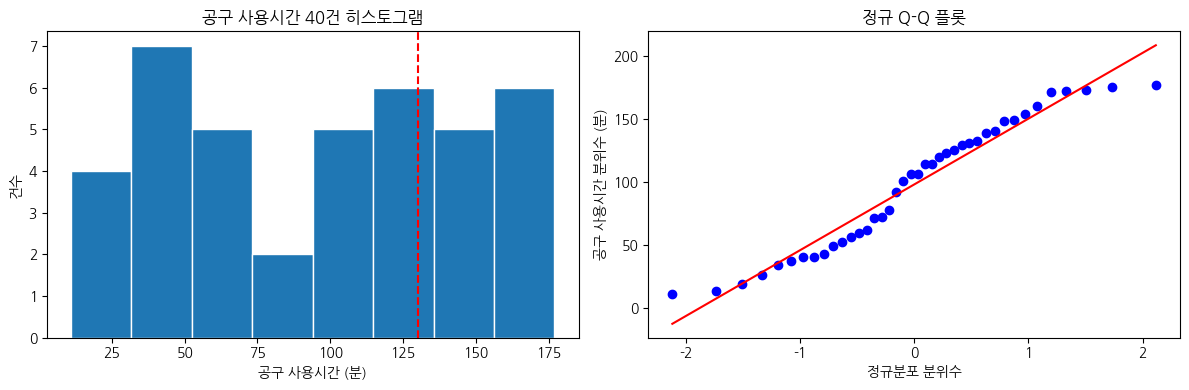

평균: 97.8 / 중앙값: 106.0
Shapiro-Wilk p값: 0.0341
기준값보다 큰 값: 13 / 작은 값: 27
Wilcoxon 통계량: 177.0 / p값: 0.0017


In [ ]:
# [예제] 공구 사용시간 40건으로 중앙값이 기준값 130분과 다른지 검정한다
# 귀무가설(H₀): 공구 사용시간의 중앙값은 130분이다. (M = 130)
# 대립가설(H₁): 공구 사용시간의 중앙값은 130분과 다르다. (M ≠ 130)
# 유의수준 α = 0.05, 양측
tool = data["Tool wear [min]"].sample(n=40, replace=False, random_state=35)   # 공구 사용시간 표본 40건

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(tool, bins=8, edgecolor="white")                 # 좌우가 대체로 대칭인지, 종 모양인지 확인
axes[0].axvline(130, color="red", linestyle="--")             # 기준값 130분 위치
axes[0].set(title="공구 사용시간 40건 히스토그램", xlabel="공구 사용시간 (분)", ylabel="건수")
stats.probplot(tool, dist="norm", plot=axes[1])               # 정규성 확인
axes[1].set(title="정규 Q-Q 플롯", xlabel="정규분포 분위수", ylabel="공구 사용시간 분위수 (분)")
plt.tight_layout()
plt.show()

print("평균:", round(tool.mean(), 1), "/ 중앙값:", tool.median())                 # 참고 지표 : 대칭이면 평균과 중앙값이 가깝다 (가깝다고 대칭인 것은 아니다)
print("Shapiro-Wilk p값:", round(stats.shapiro(tool).pvalue, 4))                 # 정규성 확인
print("기준값보다 큰 값:", (tool > 130).sum(), "/ 작은 값:", (tool < 130).sum())    # 기준값 위·아래 건수

tool_result = stats.wilcoxon(tool - 130)                      # 기준값을 뺀 차이로 검정
print("Wilcoxon 통계량:", tool_result.statistic, "/ p값:", round(tool_result.pvalue, 4))

# [결과]
# - Shapiro-Wilk p = 0.0341 < 0.05. 히스토그램이 종 모양이 아니라 넓게 고르게 퍼져 있고, Q-Q 점이 양 끝에서 직선을 벗어난다 → 정규성이 어긋난다
# - 히스토그램에서 중심 양쪽의 모양이 비슷해 대체로 대칭이다 (평균 97.8분, 중앙값 106분도 가깝다) → Wilcoxon 부호순위검정을 쓴다
# - 큰 값 13건, 작은 값 27건, p = 0.0017
# - 통계적 결론 : p = 0.0017 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 공구 사용시간의 중앙값은 130분과 다르다고 볼 통계적 근거가 있다. 표본 중앙값은 106분으로 기준보다 짧다 (n = 40)

In [ ]:
# [실습]
# 상황 : 설비팀은 공구 사용시간의 기준을 110분으로 보고 있다. 같은 공구 사용시간 40건으로 이 기준값을 검정한다.
#        귀무가설(H₀): 공구 사용시간의 중앙값은 110분이다. (M = 110)
#        대립가설(H₁): 공구 사용시간의 중앙값은 110분과 다르다. (M ≠ 110)
#        유의수준 α = 0.05, 양측
# 기준값보다 큰 값과 작은 값의 건수를 세고, Wilcoxon 부호순위검정의 p값을 구해 통계적 결론과 사실적 결론을 쓰시오.



### 참고 : 분포가 한쪽으로 크게 치우쳤을 때

측정값 − 기준값의 분포가 한쪽으로 크게 치우치면 Wilcoxon 부호순위검정의 결과를 중앙값으로 읽을 수 없다. 이때는 다음 두 방법 중 하나를 쓴다.

| 방법 | 가설 | 함수 |
|---|---|---|
| 부호검정 | 귀무가설(H₀): 중앙값은 기준값이다. (M = 기준값)<br>대립가설(H₁): 중앙값은 기준값과 다르다. (M ≠ 기준값) | `stats.binomtest(큰 값 개수, n=큰 값 개수 + 작은 값 개수, p=0.5)` |
| Wilcoxon 부호순위검정 (공식 문서의 정의대로 해석) | 귀무가설(H₀): 측정값에서 기준값을 뺀 차이는 0을 중심으로 대칭으로 분포한다.<br>대립가설(H₁): 측정값에서 기준값을 뺀 차이는 0을 중심으로 대칭으로 분포하지 않는다. | `stats.wilcoxon(x - 기준값)` |

**부호검정**은 기준값보다 큰 값과 작은 값의 **개수만** 센다. 중앙값이 기준값이라면 큰 값과 작은 값이 반반(확률 0.5)으로 나와야 한다는 원리를 이용한다. 대칭 조건이 필요 없다. 기준값과 같은 값은 세지 않는다.

**Wilcoxon 부호순위검정의 공식 정의** : scipy 공식 문서는 이 검정의 귀무가설을 "차이의 분포가 0을 중심으로 대칭이다"로 정의한다. 대칭인 자료에서는 이 가설이 "중앙값 = 기준값"과 같은 뜻이므로 여기서는 중앙값 형식으로 쓴다. 치우친 자료에 Wilcoxon 부호순위검정을 쓸 때는 공식 문서의 정의대로 가설과 결론을 쓴다.

- 귀무가설(H₀): 회전속도에서 1,550을 뺀 차이는 0을 중심으로 대칭으로 분포한다.
- 대립가설(H₁): 회전속도에서 1,550을 뺀 차이는 0을 중심으로 대칭으로 분포하지 않는다.
- 사실적 결론 : 회전속도는 1,550 rpm을 중심으로 좌우 대칭으로 분포한다고 보기 어렵다. 표본에서 30건 중 22건이 1,550 rpm보다 낮다.

공식 문서 : [scipy.stats.wilcoxon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html) · [scipy.stats.binomtest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html)

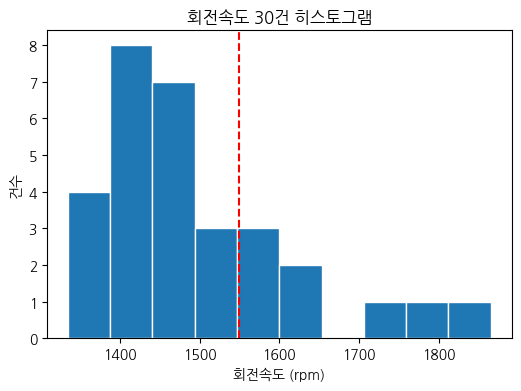

평균: 1493.4 / 중앙값: 1451.0
기준값보다 큰 값: 8 / 작은 값: 22
부호검정 p값: 0.0161
Wilcoxon p값: 0.0111


In [ ]:
# [예제] 참고 : 오른쪽 꼬리가 긴 회전속도 30건을 기준값 1,550 rpm 과 비교한다
speed = data["Rotational speed [rpm]"].sample(n=30, replace=False, random_state=42)   # 회전속도 표본 30건

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(speed, bins=10, edgecolor="white")                    # 한쪽으로 치우쳤는지 확인
ax.axvline(1550, color="red", linestyle="--")                 # 기준값 1,550 rpm 위치
ax.set(title="회전속도 30건 히스토그램", xlabel="회전속도 (rpm)", ylabel="건수")
plt.show()

print("평균:", round(speed.mean(), 1), "/ 중앙값:", speed.median())              # 치우친 자료는 평균과 중앙값이 벌어진다
n_above = (speed > 1550).sum()                                # 기준값보다 큰 값의 개수
n_below = (speed < 1550).sum()                                # 기준값보다 작은 값의 개수
print("기준값보다 큰 값:", n_above, "/ 작은 값:", n_below)

# 1) 부호검정(Sign Test) — 중앙값 비교
# 귀무가설(H₀): 회전속도의 중앙값은 1,550 rpm이다. (M = 1,550)
# 대립가설(H₁): 회전속도의 중앙값은 1,550 rpm과 다르다. (M ≠ 1,550)
# 기준보다 높은 값과 낮은 값의 개수를 비교한다.

sign_result = stats.binomtest(n_above, n=n_above + n_below, p=0.5)   # 중앙값이 1,550 이면 큰 값 비율이 0.5
print("부호검정 p값:", round(sign_result.pvalue, 4))

# 2) Wilcoxon [윌콕슨] 부호순위검정
# 귀무가설(H₀): 회전속도는 1,550 rpm을 중심으로 대칭으로 분포한다. (차이의 중앙값 = 0)
# 대립가설(H₁): 회전속도는 1,550 rpm을 중심으로 대칭으로 분포하지 않는다. (차이의 중앙값 ≠ 0)
# 기준값과의 차이에 대해 부호와 순위를 이용한다.
print("Wilcoxon p값:", round(stats.wilcoxon(speed - 1550).pvalue, 4))

# [결과]
# - 평균 1,493.4 > 중앙값 1,451, 오른쪽 꼬리가 길다 → 좌우 대칭이 아니다
# - 부호검정 : 1,550 rpm보다 높은 기록 8건, 낮은 기록 22건, p = 0.0161
#   통계적 결론 : p = 0.0161 < 0.05 이므로 귀무가설을 기각한다
#   사실적 결론 : 회전속도의 중앙값은 1,550 rpm과 다르다. 표본 중앙값은 1,451 rpm으로 기준값보다 낮다 (n = 30)
# - Wilcoxon 부호순위검정 : p = 0.0111
#   통계적 결론 : p = 0.0111 < 0.05 이므로 귀무가설을 기각한다
#   사실적 결론 : 회전속도는 1,550 rpm을 중심으로 좌우 대칭으로 분포한다고 보기 어렵다
# - 이 자료는 좌우 대칭이 아니어서 Wilcoxon 부호순위검정의 조건에 맞지 않는다
#   중앙값이 1,550 rpm과 다른지는 부호검정 결과로 판단한다

## 8. 정리 : 추정과 가설검정

### 핵심 개념

| 개념 | 뜻 |
|---|---|
| 모집단 · 모수 | 결론을 적용할 대상 전체와 그 특성값 (μ, σ, p) |
| 표본 · 통계량 | 실제로 조사한 일부와 거기서 계산한 값 (x̄, s, p̂) |
| 표준편차 (SD) | 개별 값의 퍼짐 |
| 표준오차 (SE) | 표본평균 분포의 표준편차. s ÷ √n으로 추정한다 |
| 중심극한정리 | n이 커질수록 표본평균의 분포가 정규분포에 가까워진다 |
| 신뢰구간 | 추정값 ± 임계값 × 표준오차. 같은 방법을 반복하면 만든 구간의 약 95%가 모평균을 포함한다 |
| 귀무가설 · 대립가설 | 검정의 기준이 되는 가설과 입증하려는 주장 |
| 검정통계량 t | (표본평균 − 기준값) ÷ 표준오차. 표준오차 몇 개만큼 떨어졌는가 |
| p값 | H₀가 참이라고 할 때 지금 결과만큼 또는 더 극단적인 결과가 나올 확률. H₀가 참일 확률이 아니다 |
| 유의수준 α | H₀가 참인데 기각하는 위험을 어디까지 허용할지 미리 정한 기준 (보통 0.05) |
| 제1종 · 제2종 오류 | 차이가 없는데 있다고 판단 / 실제 차이를 놓침 |

### 가설검정 4단계

1) 가설 설정 : 귀무가설(H₀)과 대립가설(H₁)을 문장과 기호로 쓴다
   - 귀무가설(H₀): 모집단의 평균 토크는 40 N·m이다. (μ = 40)
   - 대립가설(H₁): 모집단의 평균 토크는 40 N·m와 다르다. (μ ≠ 40)
2) 유의수준과 방향 : 데이터를 보기 전에 α와 양측·단측을 정한다
3) 정규성 확인 → 검정 선택 : 크게 어긋나지 않으면 t검정, 크게 어긋나면 비모수 검정
4) 결과 도출 : p값과 α를 비교하고, 신뢰구간과 함께 두 줄로 결론을 쓴다

### 검정 선택

| 검정 | 정규성 확인 대상 | 크게 어긋나지 않을 때 | 크게 어긋날 때 |
|---|---|---|---|
| 일표본 | 측정값 | `stats.ttest_1samp(x, 기준값)` | `stats.wilcoxon(x - 기준값)` |
| 대응표본 | 전·후 차이 | `stats.ttest_rel(after, before)` | `stats.wilcoxon(after, before)` |
| 독립 두 집단 | 두 집단 각각 | `stats.ttest_ind(A, B, equal_var=False)` | `stats.mannwhitneyu(A, B)` |

- 정규성 확인 : 데이터 5,000개 이하는 `stats.shapiro`, 5,000개 초과는 `stats.normaltest`를 쓰고, 히스토그램·Q-Q 플롯과 함께 판단한다.
- 검정은 정규성 p값 하나로 정하지 않는다. 먼저 비교할 대상(평균인지, 중앙값·분포인지)을 정하고, 표본 크기 · 분포 모양 · 극단값을 함께 본다.
- Wilcoxon 부호순위검정은 측정값 − 기준값(대응표본은 차이값)의 분포가 대체로 좌우 대칭일 때 쓴다. 한쪽으로 크게 치우치면 부호검정(`stats.binomtest`)으로 중앙값을 검정한다.
- 독립 두 집단은 데이터 수가 같든 다르든 Welch t검정(`equal_var=False`)을 쓴다. `ttest_ind`의 기본값은 등분산을 가정하는 방식이다.
- 검정 방향은 세 함수 모두 `alternative="two-sided"`(기본) · `"greater"` · `"less"`로 정한다.

### 결론 문장

| p값 | 통계적 결론 | 사실적 결론 |
|---|---|---|
| p < α | 귀무가설을 기각한다 | ~와 다르다고 볼 통계적 근거가 있다 (관측값과 신뢰구간 함께) |
| p ≥ α | 귀무가설을 기각하지 못한다 | ~와 다르다고 볼 통계적 근거가 부족하다 (관측값과 신뢰구간 함께) |

### 해석 시 유의점

| 항목 | 해석 기준 |
|---|---|
| p값 | 귀무가설이 참이라고 가정할 때 관측된 결과 또는 더 극단적인 결과가 나올 확률이다. 귀무가설이 참일 확률이 아니다 |
| 귀무가설을 기각하지 못함 | 기각할 통계적 근거가 부족하다는 뜻이며, 귀무가설이 참임을 입증한 것이 아니다 |
| 중심극한정리 | 표본 크기가 커질수록 표본평균의 분포가 정규분포에 가까워진다는 정리다. 원자료의 분포는 바뀌지 않는다 |
| 신뢰구간 | 모수(모평균)를 추정한 구간이다. 개별 관측값이 들어갈 범위를 나타내지 않는다 |
| 비모수 검정 | 정규분포를 가정하지 않는다. 결론은 각 검정의 귀무가설에 맞춰 쓴다 (예: Wilcoxon 부호순위검정은 중앙값) |
| Wilcoxon 부호순위검정 | 차이의 분포가 대체로 대칭일 때 중앙값으로 해석한다. 한쪽으로 크게 치우친 자료는 부호검정으로 중앙값을 검정한다 |
| 정규성 검정의 p값 | 검정 방법을 선택하기 위한 값이며, 본 검정(평균 비교)의 p값과 구분한다 |

공식 문서 : [scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html) · [NIST : Hypothesis tests](https://www.itl.nist.gov/div898/handbook/prc/section1/prc13.htm) · [ASA Statement on p-Values](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf)

## 참고 : 지수 표기법

`1.9e-06`처럼 출력되는 형식을 **지수 표기법**(과학적 표기법)이라고 한다. `e`는 지수(exponent)의 첫 글자이며, `e-06`은 10의 −6제곱, 즉 소수점을 왼쪽으로 6칸 옮긴다는 뜻이다.

| 출력 | 읽기 | 소수 | 결론에 쓸 때 |
|---|---|---|---|
| `1.9e-06` | 1.9 곱하기 10의 −6제곱 (1.9 × 10⁻⁶) | 0.0000019 | p < 0.001 |
| `2.5e-05` | 2.5 곱하기 10의 −5제곱 (2.5 × 10⁻⁵) | 0.000025 | p < 0.001 |
| `3.2e+04` | 3.2 곱하기 10의 4제곱 (3.2 × 10⁴) | 32,000 | |

- `round(p값, 4)`로 출력하면 아주 작은 p값이 `0.0`으로 보일 수 있다. 소수 넷째 자리에서 반올림된 것이며 p값이 0인 것은 아니다.
- p값이 0.001보다 작으면 결론에는 "p < 0.001"로 쓴다.

공식 문서 : [Python 문서 : 부동소수점 리터럴](https://docs.python.org/ko/3.13/reference/lexical_analysis.html#floating-point-literals)